# **Gaussian Processes (Nando de Freitas)**

In [1]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt

# 1. Sampling from a 1D Gaussian distribution

Suppose we are given a Gaussian distribution specified by the mean $\mu$ and the variance $\sigma^2$. The Gaussian PDF is then given in `scipy` by `scipy.stats.norm.pdf`:

Text(0.5, 1.0, 'Gaussian PDF')

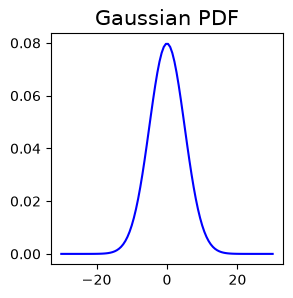

In [23]:
mu = 0
sigma = 5

x = np.linspace(-30, 30, 100)
pdf = sp.stats.norm.pdf(x, loc=mu, scale=sigma) # Gaussian from scipy

fig1, ax1 = plt.subplots(1, 1, figsize=(3, 3))
ax1.plot(x, pdf, c="blue")
ax1.set_title("Gaussian PDF", fontsize = 15)

How do we sample from this Gaussian? Well, let us first plot the CDF of this function:

Text(0.5, 1.0, 'Gaussian CDF')

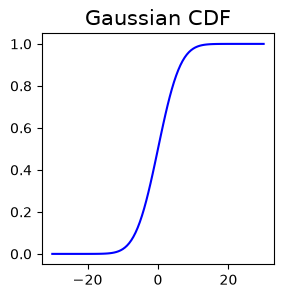

In [22]:
cdf = sp.stats.norm.cdf(x, loc=mu, scale=sigma) # Gaussian from scipy

fig2, ax2 = plt.subplots(1, 1, figsize=(3, 3))
ax2.plot(x, cdf, c="blue")
ax2.set_title("Gaussian CDF", fontsize = 15)

Notice that the CDF approaches $0$ as $x\to-\infty$ and approaches $1$ as $x\to + \infty$. This gives us a way to sample the Gaussian distribution. We assume a uniform distribution of numbers between $0$ and $1$. Then, by sampling a random number of this uniform distribution, we can map it back to a point on the CDF (the point is unique since the CDF is monotonic). The point on the CDF can then be mapped back to the original Gaussian PDF and this would allow us to sample the Gaussian. 

In [36]:
uniform_samples = np.random.uniform(0, 1, 5000) # draw 5000 numbers between 0 and 1
gaussian_samples = sp.stats.norm.ppf(uniform_samples, loc=mu, scale=sigma)

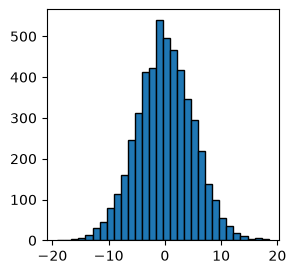

In [ ]:
fig3, ax3 = plt.subplots(1, 1, figsize=(3,3))
ax3.hist(gaussian_samples, bins=30, edgecolor="black")
plt.show()

Notice that we recover a bell-shape object which follows our values of $\mu$ and $\sigma$ as expected. 

We note here that for any given Gaussian $x_i \sim \mathcal{N}(\mu, \sigma^2)$, it can be mapped to the standard normal distribution via:
$$
x_i \sim \mathcal{N}(\mu, \sigma^2) \sim \mu + \sigma \mathcal{N}(0, 1).
\tag{1}
$$

# 2. Generating random vectors

## 2.1 Uncorrelated standard normal Gaussian distribution

We just demonstrated how to sample a point randomly from a general Gaussian distribution. How can we extend this to multivariate Gaussians to generate random vectors? For example in the 2D case, we may want to draw from:
$$
\begin{bmatrix} x_1 \\ x_2 \end{bmatrix}_i 
\sim 
\mathcal{N} \left( 
    \begin{bmatrix} 0 \\ 0 \end{bmatrix}
    ,
    \begin{bmatrix} 1 & 0 \\ 0 & 1\end{bmatrix}
\right)
.
\tag{2}
$$

This is where the **matrix inversion lemma** (see theorem 4.3.1 of Kevin Murphy, 2015) becomes critical. Note that in the above, because the off-diagonal elements of the covariance matrix is $0$, $x_1$ and $x_2$ are not correlated.

> <u>**Matrix Inversion Lemma**</u>
>
> Suppose $\bm{x} = [x_1, x_2]$ is jointly Gaussian with the parameters $\bm{\mu} = [\mu_1, \mu_2]$ and a covariance matrix given by:
>$$
\bm{\Sigma} = \begin{bmatrix} \Sigma_{11} & \Sigma_{12} \\ \Sigma_{21} & \Sigma_{22} \end{bmatrix}
.
\tag{3}
>$$
>
>The marginal distributions are then given by:
>$$
\begin{align}
    &
    p(x_1) = \mathcal{N}(x_1|\mu_1, \Sigma_{11})
    ,
    \tag{4}
    \\
    &
    p(x_2) = \mathcal{N}(x_2|\mu_2, \Sigma_{22})
    . 
    \tag{5}
\end{align}
>$$
>Note the $|$ in equations $(4)$ and $(5)$ does NOT indicate a conditional distribution. It is just >separating the random variable $x_1$ from its parameters $\mu_1$ and $\Sigma_{11}$. Moreover, the posterior conditional is given by:
>$$
\begin{align}
    &
    p(x_1 | x_2) = \mathcal{N} (x_1 | \bm{\mu}_{1|2}, \bm{\Sigma}_{1|2})
    , \tag{5.1}
    \\
    &
    \mu_{1|2} = \mu_1 + \Sigma_{12} \Sigma_{22}^{-1} (x_2 - \mu_2)
    , \tag{5.2}
    \\
    &
    \Sigma_{1|2} = \Sigma_{11} - \Sigma_{12}\Sigma_{22}^{-1} \Sigma_{21}
    . \tag{5.3}
\end{align}
>$$

Using $(4)$ and $(5)$ on $(2)$ gives:
$$
\begin{align}
    &x_1 \sim \mathcal{N}(0, 1)
    , \tag{6}
    \\
    &x_2 \sim \mathcal{N}(0, 1)
    . \tag{7}
\end{align}
$$

This is simply telling us that drawing $x_1$ and $x_2$ is akin to drawing individual 1D Gaussian's separately for each element in the vector as we had done previously.

## 2.2 General multivariate gaussian

Let us now consider something more general:
$$
\begin{bmatrix}
    x_1 \\ x_2 
\end{bmatrix}
\sim 
\mathcal{N} \left( 
    \begin{bmatrix} \mu_1 \\ \mu_2 \end{bmatrix}
    ,
    \begin{bmatrix} \Sigma_{11} & \Sigma_{12} \\ \Sigma_{21} & \Sigma_{22}\end{bmatrix}
\right)
.
\tag{8}
$$

In this case, we really want to use the identity $(1)$ for the 1D case. This means we somehow need to obtain a 'square root' of a matrix. In other words, if $\bm{x} \sim \mathcal{N}(\bm{\mu}, \bm{\Sigma})$, then we hope we can do something like:
$$
    \bm{x} \sim \bm{\mu} + \pmb{\mathsf{L}} \mathcal{N}(0, \pmb{\mathsf{I}})
    ,
    \tag{9}
$$

where $\pmb{\mathsf{I}}$ is the identity matrix seen in $(2)$ and $\pmb{\mathsf{L}}$ represents the 'square root' of the covariance matrix.

> <u> **Cholesky Decomposition** </u>
>
> This will be our definition of what a 'square root' of a matrix is. The covariance matrix $\bm{\Sigma}$ can always be written as:
> $$
\bm{\Sigma} = \pmb{\mathsf{L}}\pmb{\mathsf{L}}^T
. \tag{10}
> $$
> Note that this only works because the covariance matrix is *symmetric positive definite*.

We will later demonstrate how to use this to sample general multivariate Gaussians.

# 3. Gaussian Process Regression

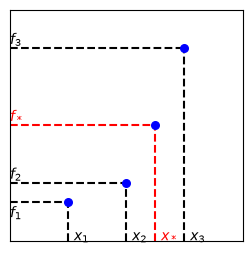

In [29]:
fig4, ax4 = plt.subplots(1, 1, figsize = (3, 3))

x = [1, 2, 2.5, 3]
y = [1, 1.5, 3, 5]

ax4.vlines(1, ymin=0, ymax=1, linestyle="--", color="black", zorder=0)
ax4.hlines(1, xmin=0, xmax=1, linestyle="--", color="black", zorder=0)
ax4.annotate(r"$x_1$", xy=(1.1,0))
ax4.annotate(r"$f_1$", xy=(0,0.6))
ax4.vlines(2, ymin=0, ymax=1.5, linestyle="--", color="black", zorder=0)
ax4.hlines(1.5,xmin=0, xmax=2, linestyle="--", color="black", zorder=0)
ax4.annotate(r"$x_2$", xy=(2.1,0))
ax4.annotate(r"$f_2$", xy=(0,1.6))
ax4.vlines(3, ymin=0, ymax=5, linestyle="--", color="black", zorder=0)
ax4.hlines(5, xmin=0, xmax=3, linestyle="--", color="black", zorder=0)
ax4.annotate(r"$x_3$", xy=(3.1,0))
ax4.annotate(r"$f_3$", xy=(0,5.1))
ax4.vlines(2.5, ymin=0, ymax=3, linestyle="--", color="red", zorder=0)
ax4.hlines(3, xmin=0, xmax=2.5, linestyle="--", color="red", zorder=0)
ax4.annotate(r"$x_*$", xy=(2.6,0), color='red')
ax4.annotate(r"$f_*$", xy=(0,3.1), color='red')
ax4.scatter(x, y, marker='o', s=30, c="blue", zorder=1)
# ax4.set_xlabel("x")
# ax4.set_ylabel("f", rotation = 0)
ax4.set_xlim(0, 4)
ax4.set_ylim(0, 6)
ax4.set_xticks([])
ax4.set_yticks([])
plt.show()

Suppose you are given the data points $(x_1 f_1)$, $(x_2, f_2)$, and $(x_3, f_3)$ where $x_1 < x_2 < x_3$ and $f_1 < f_2 < f_3$. We wish to model the $f$'s given the $x$'s. For simplicity, let us assume that:
$$
\bm{f} \equiv
\begin{bmatrix} f_1 \\ f_2 \\ f_3 \end{bmatrix}
\sim 
\mathcal{N} \left(
    \begin{bmatrix} 0 \\ 0 \\ 0 \end{bmatrix}
    ,
    \begin{bmatrix} \mathsf{K}_{11} & \mathsf{K}_{12} & \mathsf{K}_{13} \\ \mathsf{K}_{21} & \mathsf{K}_{22} & \mathsf{K}_{23} \\ \mathsf{K}_{31} & \mathsf{K}_{32} & \mathsf{K}_{33} \end{bmatrix}
\right)
. \tag{11}
$$

We expect the points $(x_1, f_1)$ to be more correlated to $(x_2, f_2)$ then $(x_3, f_3)$ because they are more nearby. In this case, we expect a covariance matrix that is something like:
$$
\pmb{\mathsf{K}}
=
\begin{bmatrix} 1 & 0.7 & 0.2 \\ 0.7 & 1 & 0.6 \\ 0.2 & 0.6 & 1  \end{bmatrix}
.
\tag{12}
$$

This reflects the strength of the correlation between the different points. But how do we construct this matrix exactly?

The way to do so is to somehow let the elements $\mathsf{K}_{ij}$ be some measure of similarity. There are many ways, one of which, is the *squared exponential kernel* (note that there are many version of kernels to use):

> <u> **Squared exponential kernel** </u>
>$$
\mathsf{K}_{ij} = e^{-\lVert x_i - x_j \rVert^2}
= 
\begin{dcases}
    0 & \text{if } \lVert x_i - x_j \rVert \to \infty 
    \\
    1 & \text{if } x_i = x_j
\end{dcases}
\tag{13}
>$$

We only use the points $x_i$ to construct $\mathsf{K}_{ij}$; however, the model (distribution) we are interested in describes $f_i$ and has nothing to do with $x_i$.

Suppose now we are given another point $x_*$, we wish to find the corresponding $f_*$. Since we know that $\bm{f} \sim \mathcal{N}(0, \pmb{\mathsf{K}})$ and we expect the test data to follow the same distribution as the training data, we also expect it to have mean $0$. Hence:
$$
f_* \sim \mathcal{N} (0, \mathsf{K}(x_*, x_*))
 =  \mathcal{N} (0, 1)
, \tag{14}
$$
where using $(13)$, it is clear that $\mathsf{K}_{**} = \mathsf{K}(x_*, x_*) = 1$. What we expect, combining with $\bm{f}$ in $(11)$ is then that:
$$
\begin{aligned}
    \begin{bmatrix} \bm{f} \\ f_* \end{bmatrix}
    &\sim 
    \mathcal{N} \left(
        \bm{0}, 
        \begin{bmatrix}
            \mathsf{K}_{11} & \mathsf{K}_{12} & \mathsf{K}_{13} & \mathsf{K}_{1*}
            \\
            \mathsf{K}_{21} & \mathsf{K}_{22} & \mathsf{K}_{23} & \mathsf{K}_{2*}
            \\
            \mathsf{K}_{31} & \mathsf{K}_{32} & \mathsf{K}_{33} & \mathsf{K}_{3*}
            \\
            \mathsf{K}_{*1} & \mathsf{K}_{*2} & \mathsf{K}_{*3} & \mathsf{K}_{**}
            \\
        \end{bmatrix}
    \right)
    \\
    &=
    \mathcal{N} \left( 
        \bm{0},
        \begin{bmatrix}
            \pmb{\mathsf{K}} & \bm{K}_* \\ \bm{K}_*^T & \mathsf{K}_{**}
        \end{bmatrix}
    \right)
    ,
\end{aligned}
\tag{15}
$$

where $\bm{K}_*$ is a vector and $\mathsf{K}_{**}$ is a scalar. This is a *joint distribution* over $f$ and $f_*$. 


How can we obtain the CONDITIONAL distribution $p(f_* | \bm{f})$? This is where equations $(5.2)$ and $(5.3)$ come in from the matrix inversion lemma to give us:
$$
\begin{align}
    &
    \mu_{f_*|\bm{f}} = \mu_{f_*} + \bm{K}_*^T \pmb{\mathsf{K}}^{-1} \left(\bm{f} - \bm{\mu}_{\bm{f}} \right)  
    = \bm{K}_* \mathsf{K}_{**}^{-1} \bm{f}
    ,
    \tag{16}
    \\
    &
    \mathsf{K}_{f_*|\bm{f}} = \mathsf{K}_{**} - \bm{K}_*^T \pmb{\mathsf{K}}^{-1} \bm{K}_* 
    . \tag{17}
\end{align}
$$
where we have used the fact that $\mu_{f_*} = 0$ and $\bm{\mu}_{\bm{f}} = \bm{0}$. Therefore, given any point in the test set $f_*$, you can predict where the mean would be and what is the confidence interval (the variance from $(17)$). 

You might be wondering why a mean is even involved since for each $x_*$, shouldn't we be predicting just a single value of $f_*$? The reason is that MANY functions passes through the test point, therefore our "expectation" is the conditional mean, which is the value that we report. This is exactly what figure 2.2 in Rasmussen & Williams (2005, 2nd ed) is trying to tell us.

## 3.1 Intuition behind a Gaussian process

Now that we know that for any $x_*$, we can do it for ANY number of $x_*$ (even an infinite number of it). This gives us the entire function, which is the idea behind the Gaussian process. 

><u> **Definition of the Gaussian process (GP)** </u>
>
>A GP is a Gaussian distribution over functions:
>$$
f(\bm{x}) \sim GP (m(\bm{x}), \kappa(\bm{x}, \bm{x}'))
,
\tag{18}
>$$
>where $m(\bm{x}) = \mathbb{E}[f(\bm{x})]$ and:
>$$
\kappa(\bm{x}, \bm{x}') = \mathbb{E} \left[
    \left( f(\bm{x}) - m(\bm{x}) \right) \left( f(\bm{x}') - m(\bm{x}') \right)^T
\right]
.
\tag{19}
>$$

So when you pass in a parameter $\bm{x}$, you get the CONDITIONAL MEAN $\mu_{\bm{x}}$. It is a distribution over functions precisely because these conditional mean and variances themselves are functions of $\bm{x}$.

For clarity, we reiterate how a GP regression should be done.

1. Start with a set of test points $x_1, \cdots, x_N$.
2. Decide what the mean $\bm{\mu}_{N\times 1}$ of these test points is.
3. Use the kernel (e.g. exponential mean squared) to compute the covariance matrix $\pmb{\mathsf{K}}_{N\times N}$
4. Perform a Cholesky decomposition (10) on $\pmb{\mathsf{K}}_{N\times N}$ to get $\pmb{\mathsf{K}}_{N\times N} = \pmb{\mathsf{L}} \pmb{\mathsf{L}}^T$.
5. Draw samples $\bm{f}_i \sim \mathcal{N}(\bm{\mu}_{N\times 1}, \pmb{\mathsf{K}}_{N\times N})$ by using equation $(9)$:
$$
\bm{f}_i \sim \bm{\mu}_{1\times N} + \pmb{\mathsf{L}}\mathcal{N}(0, \pmb{\mathsf{I}})
.
\tag{20}
$$
Each sample $\bm{f}_i$ is a vector $[f_1, \cdots, f_N]$ which is representative of the sample function we are interested in.

## 3.2 Making predictions using a GP (Noiseless)

Suppose we are now given a training dataset $\mathcal{D} = \{(\bm{x}_i, f_i), i = 1, \cdots, n\}$ where $f_i = f(\bm{x}_i)$. We can now specify a *prior* that we want these functions to be smooth, this can be done through the covariance (equivalently the kernel). In other words, by using the mean squared kernel, we encode the PRIOR knowledge that "if two points $\bm{x}_1$ and $\bm{x}_2$ are close by, then $f_1$ and $f_2$ must also be close by", which is what continuity is.


Given a test set $\bm{X}_*$ of size $N_* \times D$, we wish to predict what the function outputs $\bm{f}_*$ are. Similar to what we have done in $(15)$, we assume that:
$$
\begin{bmatrix}
    \bm{f} \\ \bm{f}_*
\end{bmatrix}
\sim 
\mathcal{N} \left(
    \begin{bmatrix} \bm{\mu} \\ \bm{\mu}_* \end{bmatrix}
    ,
    \begin{bmatrix} \pmb{\mathsf{K}} & \pmb{\mathsf{K}}_* \\ \pmb{\mathsf{K}}_*^T & \pmb{\mathsf{K}}_{**} \end{bmatrix}
\right)
,
\tag{21}
$$
where $\pmb{\mathsf{K}} = \kappa(\bm{X}, \bm{X})$ is $N\times N$, $\pmb{\mathsf{K}}_{*} = \kappa(\bm{X}, \bm{X}_*)$ is $N\times N_*$, and $\pmb{\mathsf{K}}_{**} = \kappa(\bm{X}_*, \bm{X}_*)$ is $N_* \times N_*$. Here, $\kappa$ is our kernel:
$$
\kappa(x, x') = \sigma_f^2 \exp \left[
    -\frac{(x-x')^2}{2\ell^2}
\right]
. \tag{22}
$$
Unlike the previous exponential squared kernel, there are extra parameters $\sigma_f$ and $\ell$. The parameter $\ell$ tells how close by something is to be considered "similar"


Invoking the *matrix inversion lemma* again, we know that:
$$
\begin{align}
    & 
    p(\bm{f}_* | \bm{X}_*, \bm{X}, \bm{f}) = \mathcal{N}(\bm{f}_* | \bm{\mu}_*, \bm{\Sigma}_*)
    ,
    \tag{23}
    \\
    &
    \bm{\mu}_{\bm{f}_*|\bm{f}} = \bm{\mu}(\bm{X}_*) + \pmb{\mathsf{K}}_*^T \pmb{\mathsf{K}}^{-1} \left( \bm{f} - \bm{\mu}(\bm{X}) \right)
    , \tag{24}
    \\
    &
    \bm{\Sigma}_{\bm{f}_* | \bm{f}} = \pmb{\mathsf{K}}_{**} - \pmb{\mathsf{K}}_*^T \pmb{\mathsf{K}}^{-1} \pmb{\mathsf{K}}_*. 
    \tag{25}
\end{align}
$$
Equation $(24)$ gives us the graph to plot as our prediction and $(25)$ gives us the confidence intervals. Moreover, since $(23)$ is a Gaussian, we can draw samples from the Gaussian as we had done previously. 

In [ ]:
# TODO: Do an example with a sine curve



## 3.3 Making predictions using GP (with Noise)